# EpiEEG-60: третья больница для внешней проверки REVE v4 (Г1)

| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-10-29 |
| **Гипотеза** | Г1 (ЭЭГ) |
| **Ядра Kaggle** | часть 1 — `zakharsann/h1-epieeg60-prep` (CPU, 3,4 мин): скачивание, структура, утечки, подготовка; часть 2 — `zakharsann/h1-epieeg60-reve` (GPU T4, 4,8 мин): вывод REVE v4 и метрики; часть 3 — `zakharsann/h1-epieeg60-dates` (CPU): даты в служебных файлах |
| **Набор** | EpiEEG-60, Mendeley Data 10.17632/gg88rc79vv v4, CC BY 4.0; NINS (Дакка), Nihon Kohden. Данные скачиваются внутри ядра, в git не лежат |
| **Модель** | REVE v4 (обучена на NMT train), без дообучения; ансамбль 3 запусков. EEG-DINO не считалась: дообученные веса не сохранялись (в выходах `h1-eegdino-finetune`, `h1-eegdino-seed2` только csv) |
| **Результаты** | `h1_eeg/results/epieeg60_*.csv`, `h1_eeg/results/figures/epieeg60_reve_v4.png` |

Блокнот собран из трёх ядер: ячейки и их выводы перенесены из логов Kaggle без изменений (служебные метки ячеек убраны). В конце две локальные ячейки по небольшим csv: пересчёт столбца порога в таблице калибровки (метрики совпали с ядром) и оценки по месяцам записи.

## Выводы

**Набор.**
1. На деле **63 человека: 31 «Abnormal» (эпилепсия) и 32 «Normal»**, а не 30 / 30, как в описании. По одной записи на человека, 500 Гц, 43 канала, все 19 каналов 10–20 на месте, прибор EEG-1100C, фильтр прибора 0–250 Гц у всех.
2. Длина записи у групп одинакова: медиана 35,9 мин у нормы и 34,6 мин у эпилепсии (Манн–Уитни p = 0,50). Повторов файлов нет (md5).
3. **Возраста и пола в файлах нет** (нет файла `.PNT`, дата в заголовке пустая). Сравнить группы по возрасту и полу нельзя. В `.CMT` у каждой записи есть строка «EEG-1100C ГГММДД»: по-видимому, это дата записи, в описании набора об этом нет. Записи сделаны с 20.10.2025 по 10.01.2026. **В октябре 2025 записаны только здоровые (9 из 32)**, больные — с 29.11.2025. В целом по дате группы различаются умеренно (p = 0,22). Без этих 9 здоровых ROC AUC 0,736 (0,59–0,88) против 0,761 у всех, то есть время записи результат не объясняет.
4. Протокол одинаковый: фотостимуляция и «глаза открыты/закрыты» у 100 % записей обеих групп; гипервентиляция у 91 % нормы и 74 % больных.

**Утечки.**
5. **Пометок «Seizure Onset» и других пометок о приступах нет.** Но в `.LOG` есть **ручные пометки разрядов** («spike-and-wave», «sharp-and-wave», «sharp wave», «polyspike» и др.): 115 пометок, **у 24 из 31 больного и у 2 из 32 здоровых**. Модель эти пометки не видит (она получает только сигнал), но метку «Abnormal», судя по всему, ставили по разрядам на этой же ЭЭГ. Тот же «круговой» риск, что у TUEP.
6. Амплитуда у групп близка: СКО 39 мкВ у нормы и 45 мкВ у эпилепсии (p = 0,19). Сама амплитуда как оценка даёт ROC AUC 0,60. При этом записи в 2–3 раза «громче», чем в обучающих наборах: у здоровых 39 мкВ против 18 мкВ в NMT и 13 мкВ в Турции.

**REVE v4 без дообучения** (60 окон, среднее верхних 20 %, ансамбль 3 запусков, n = 63):

7. **ROC AUC 0,761 (95% ДИ 0,63–0,88).** По всем окнам — 0,770 (0,64–0,88), с медианой окон — 0,748 (0,62–0,86). Отдельные запуски: 0,751 / 0,745 / 0,732. Для сравнения: NMT eval 0,917, Турция 0,915. В третьей больнице качество заметно ниже.
8. **Порог NMT 0,832 переносится сюда лучше, чем в Турцию:** accuracy 0,70 (0,59–0,81), сбалансированная accuracy 0,70 (0,58–0,81), precision 0,73 (0,56–0,89), **recall 0,61 (0,43–0,78)**, специфичность 0,78 (0,63–0,91). В Турции при том же пороге recall был 0,04.
9. **Калибровка порога на месте не помогает:** сбалансированная accuracy 0,68 (0,54–0,76) при k = 10 и 0,69 (0,57–0,78) при k = 20, это не выше перенесённого порога.
10. **Связь с амплитудой — только у больных:** Спирмен +0,47 (+0,15…+0,70) у эпилепсии и +0,06 (−0,32…+0,41) у нормы.
11. **Модель хорошо узнаёт больных с размеченными разрядами и почти не узнаёт без них.** Больные с пометками (24) против всех здоровых: ROC AUC 0,807 (0,69–0,92), recall при пороге NMT 0,67. Больные без пометок (7): 0,603 (0,32–0,87), recall 0,43. Интервал широкий (всего 7 человек), но вывод тот же, что для гипотезы в целом: случаи «без явных разрядов» — самые трудные. Если выбросить окна около пометок (от −10 до +60 с), ROC AUC 0,749 (0,62–0,87), почти без изменений. Значит, оценку держат не только сами размеченные разряды.

## vEpiSet (проверка по статье)
Статья Scientific Data, 2025 (DOI 10.1038/s41597-025-04572-1, полный текст в PMC11805897). В разделе Participants: 84 пациента, из них **52 с эпилепсией и хотя бы одним разрядом** и **32 «с нормальной ЭЭГ», из которых 14 получили диагноз эпилепсии**. Здоровой контрольной группы нет: все 84 записаны в эпилептическом центре PUMCH во время длительного мониторинга, из них 20 минут выбрал врач. В аннотации и в Background все 84 названы «epilepsy patients». По людям в наборе есть только `base_info.csv` (пол, возраст) и разметка разрядов и сна. **Метки диагноза по пациентам нет**: какие 14 из 32 больны эпилепсией, из файлов не узнать. Для задачи «эпилепсия против нормы» набор не годится. Годится только для детектора разрядов (52 с разрядами против 32 без).

# EpiEEG-60, часть 1: структура набора, проверка утечек, подготовка сигнала (CPU)
| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-10-29 |
| **Гипотеза** | Г1 (ЭЭГ) |
| **Набор** | EpiEEG-60, Mendeley Data, DOI 10.17632/gg88rc79vv (v4), CC BY 4.0: 30 эпилепсия / 30 норма, NINS (Дакка), Nihon Kohden, 500 Гц. Скачивается внутри ядра, в git не кладётся |
| **Зачем** | третья больница для внешней проверки моделей, обученных на NMT (вторая — Турция) |
| **Подготовка** | как в общем наборе `h1-prep-shared`: 19 каналов 10–20 в порядке EL, средний референт по 19, 500 → 200 Гц (resample_poly), 0,1–75 Гц Баттерворт 4 (sosfiltfilt) + режекция 50 Гц (iirnotch Q=30), мкВ, float16 |
| **Выход** | `fs200/<запись>.npy` (19, n) float16; `epieeg60_records.csv`, `epieeg60_events.csv`, `epieeg60_strings.csv`, `epieeg60_group_compare.csv` |


In [ ]:
import os, glob, re, time, json, hashlib, zipfile, collections, warnings
import numpy as np, pandas as pd, scipy.signal as ss, requests
from concurrent.futures import ThreadPoolExecutor
from scipy.stats import mannwhitneyu, fisher_exact
import mne
mne.set_log_level("ERROR"); warnings.filterwarnings("ignore")
T_NB = time.time()
OUT, TMP = "/kaggle/working", "/tmp/epieeg"
os.makedirs(f"{OUT}/fs200", exist_ok=True); os.makedirs(TMP, exist_ok=True)
SFREQ, BAND, NOTCH, F16_MAX = 200, (0.1, 75.0), 50.0, 60000.0
EL = ["Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2", "F7", "F8", "T3", "T4", "T5", "T6", "Fz", "Cz", "Pz"]
TARGET = [e.upper() for e in EL]
ALIAS = {"T7": "T3", "T8": "T4", "P7": "T5", "P8": "T6"}
def norm(ch):
    c = ch.upper().replace("EEG", "").strip()
    for s in ["-REF", "-AVG", "-LE", "-AR", "-A1", "-A2"]:
        c = c.replace(s, "")
    return ALIAS.get(c.strip(" -_"), c.strip(" -_"))
SOS_BP = ss.butter(4, list(BAND), btype="bandpass", fs=SFREQ, output="sos")
B_N, A_N = ss.iirnotch(NOTCH, 30, fs=SFREQ)
def filt(X):
    """0,1–75 Гц + режекция 50 Гц — тот же код, что в h1-prep-shared."""
    return ss.filtfilt(B_N, A_N, ss.sosfiltfilt(SOS_BP, X.astype(np.float64), axis=-1), axis=-1)


## 1. Скачивание с Mendeley (публичный API) и проверка sha256


In [ ]:
API = "https://data.mendeley.com/public-api/datasets/gg88rc79vv"
ds = requests.get(API, timeout=60).json()
files = requests.get(f"{API}/files?folder_id=root&version={ds['version']}", timeout=60).json()
print("набор:", ds["name"], "| версия", ds["version"], "| лицензия:", ds.get("data_licence", {}).get("short_name"))
for f in files:
    print(f"  {f['filename']}: {f['size']/1e9:.2f} ГБ, sha256 {f['content_details']['sha256_hash'][:16]}…")

def fetch(f):
    path = f"{TMP}/{f['filename']}"
    h, n, t0 = hashlib.sha256(), 0, time.time()
    with requests.get(f["content_details"]["download_url"], stream=True, timeout=120) as r, open(path, "wb") as fo:
        r.raise_for_status()
        for chunk in r.iter_content(1 << 22):
            fo.write(chunk); h.update(chunk); n += len(chunk)
            if n // (500 << 20) != (n - len(chunk)) // (500 << 20):
                print(f"    {n/1e9:.1f} ГБ, {n/1e6/(time.time()-t0):.0f} МБ/с", flush=True)
    ok = h.hexdigest() == f["content_details"]["sha256_hash"]
    print(f"  {f['filename']}: {n/1e9:.2f} ГБ за {time.time()-t0:.0f} с, sha256 {'совпал' if ok else 'НЕ СОВПАЛ'}")
    assert ok
    return path
PATHS = {f["filename"]: fetch(f) for f in files}


набор: EpiEEG-60: A Balanced Epileptic Seizure and Normal EEG Dataset | версия 4 | лицензия: CC BY 4.0
  BUBT_EEG.zip: 4.04 ГБ, sha256 b81568af1ab30ab6…
  EpiEEG60_Basic_Process.ipynb: 0.00 ГБ, sha256 efd4ce963f55357a…
    0.5 ГБ, 75 МБ/с
    1.0 ГБ, 80 МБ/с
    1.6 ГБ, 80 МБ/с
    2.1 ГБ, 81 МБ/с
    2.6 ГБ, 65 МБ/с
    3.1 ГБ, 68 МБ/с
    3.7 ГБ, 70 МБ/с
  BUBT_EEG.zip: 4.04 ГБ за 57 с, sha256 совпал
  EpiEEG60_Basic_Process.ipynb: 0.00 ГБ за 1 с, sha256 совпал


## 2. Содержимое архива и блокнот авторов


In [ ]:
zf = zipfile.ZipFile(PATHS["BUBT_EEG.zip"])
names = [n for n in zf.namelist() if not n.endswith("/")]
ext = collections.Counter(os.path.splitext(n)[1].upper() for n in names)
print("файлов в архиве:", len(names), "| по расширению:", dict(ext))
print("примеры путей:", names[:10])
other = [n for n in names if os.path.splitext(n)[1].upper() not in {".EEG", ".21E", ".EVT", ".CMT", ".CN2", ".LOG", ".TRD", ".PNT", ".11D", ".PTE", ".BFT"}]
print("прочие файлы (не Nihon Kohden):", other[:50])
t0 = time.time(); zf.extractall(f"{TMP}/x"); print(f"распаковано за {time.time()-t0:.0f} с"); os.remove(PATHS["BUBT_EEG.zip"])

# блокнот авторов — только исходный код и текст ячеек (выводы не печатаются)
nb_a = json.load(open(PATHS["EpiEEG60_Basic_Process.ipynb"], encoding="utf-8"))
for i, c in enumerate(nb_a["cells"]):
    s = "".join(c["source"]).strip()
    if s:
        print(f"--- ячейка {i} ({c['cell_type']}) ---\n{s[:1200]}")


файлов в архиве: 566 | по расширению: {'.21E': 63, '.CMT': 63, '.CN2': 63, '.EEG': 63, '.EVT': 62, '.LOG': 63, '.TRD': 126, '.CONFIG': 63}
примеры путей: ['BUBT_EEG/Abnormal/Patient_31.21E', 'BUBT_EEG/Abnormal/Patient_31.CMT', 'BUBT_EEG/Abnormal/Patient_31.CN2', 'BUBT_EEG/Abnormal/Patient_31.EEG', 'BUBT_EEG/Abnormal/Patient_31.EVT', 'BUBT_EEG/Abnormal/Patient_31.LOG', 'BUBT_EEG/Abnormal/Patient_31.TRD/DC01.TRD', 'BUBT_EEG/Abnormal/Patient_31.TRD/DC02.TRD', 'BUBT_EEG/Abnormal/Patient_31.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_32.21E']
прочие файлы (не Nihon Kohden): ['BUBT_EEG/Abnormal/Patient_31.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_32.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_33.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_34.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_35.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_36.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_37.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_38.TRD/Trend.config', 'BUBT_EEG/Abnormal/Patient_39

## 3. Записи: каналы, частота, длительность, события, даты


In [ ]:
eegs = sorted(glob.glob(f"{TMP}/x/**/*.[Ee][Ee][Gg]", recursive=True))
def parse_path(p):
    parts = p.split("/")
    grp = next((x for x in parts if x.lower() in {"normal", "abnormal"}), "?")
    pat = next((x for x in parts if x.lower().startswith("patient")), os.path.basename(os.path.dirname(p)))
    return grp, pat
REC = pd.DataFrame([dict(path=p, group=parse_path(p)[0], patient=parse_path(p)[1]) for p in eegs])
REC["y"] = (REC.group.str.lower() == "abnormal").astype(int)
REC["person"] = REC.group + "_" + REC.patient
REC["id"] = REC.person + "_" + REC.path.map(lambda p: os.path.splitext(os.path.basename(p))[0])
print("записей .EEG:", len(REC), "| людей:", REC.person.nunique())
print(REC.groupby("group").agg(людей=("person", "nunique"), записей=("id", "size")))
print("записей на человека:", REC.groupby("person").size().value_counts().to_dict())

ASCII = re.compile(rb"[\x20-\x7e]{4,}"); U16 = re.compile(rb"(?:[\x20-\x7e]\x00){4,}")
def strings(path):
    b = open(path, "rb").read()
    return [s.decode() for s in ASCII.findall(b)] + [s.decode("utf-16le") for s in U16.findall(b)]
def sidecar(p, e):
    base = os.path.splitext(p)[0]
    hit = [q for q in glob.glob(base + ".*") if q.upper().endswith(e)]
    return hit[0] if hit else None

def header(i):
    r = REC.iloc[i]
    out = dict(id=r.id)
    try:
        raw = mne.io.read_raw_nihon(r.path, preload=False)
        md = raw.info["meas_date"]; si = raw.info.get("subject_info") or {}
        out.update(sfreq_orig=raw.info["sfreq"], n_ch=len(raw.ch_names), dur_s=raw.n_times / raw.info["sfreq"],
                   ch_names="|".join(raw.ch_names), hp_hw=raw.info["highpass"], lp_hw=raw.info["lowpass"],
                   rec_year=md.year if md else np.nan, rec_month=md.month if md else np.nan, rec_hour=md.hour if md else np.nan,
                   subj_sex=si.get("sex", np.nan), subj_birth_year=(si["birthday"].year if "birthday" in si and si["birthday"] else np.nan),
                   n_annot=len(raw.annotations), err="")
        out["annot"] = [(float(a["onset"]), float(a["duration"]), str(a["description"])) for a in raw.annotations]
    except Exception as e:
        out.update(err=f"{type(e).__name__}: {str(e)[:200]}", annot=[])
    for e in [".EVT", ".LOG", ".CMT", ".PNT"]:
        q = sidecar(r.path, e)
        out[f"has{e[1:]}"] = q is not None
        out[f"str{e[1:]}"] = strings(q) if q else []
    out["md5_eeg"] = hashlib.md5(open(r.path, "rb").read()).hexdigest()
    return out
t0 = time.time()
with ThreadPoolExecutor(4) as ex:
    H = list(ex.map(header, range(len(REC))))
H = pd.DataFrame(H)
print(f"заголовки за {time.time()-t0:.0f} с | ошибок чтения: {(H.err != '').sum()}", H.loc[H.err != "", ["id", "err"]].to_string() if (H.err != "").any() else "")
REC = REC.merge(H.drop(columns=["annot", "strEVT", "strLOG", "strCMT", "strPNT"]), on="id")
print(REC.groupby("group")[["sfreq_orig", "n_ch", "dur_s", "hp_hw", "lp_hw"]].describe().T.round(2).to_string())
print("наборы каналов:", REC.ch_names.value_counts().head(3).to_dict())
print("наличие файлов:", REC.groupby("group")[["hasEVT", "hasLOG", "hasCMT", "hasPNT"]].mean().to_dict())
print("одинаковые файлы .EEG (md5) у разных записей:", int(REC.md5_eeg.duplicated(keep=False).sum()))
print("год записи по группам:\n", pd.crosstab(REC.group, REC.rec_year))
print("пол / год рождения в заголовке (из .PNT, если есть):", REC.subj_sex.notna().sum(), REC.subj_birth_year.notna().sum())


записей .EEG: 63 | людей: 63
          людей  записей
group                   
Abnormal     31       31
Normal       32       32
записей на человека: {1: 63}
заголовки за 11 с | ошибок чтения: 0 
group             Abnormal   Normal
sfreq_orig count     31.00    32.00
           mean     500.00   500.00
           std        0.00     0.00
           min      500.00   500.00
           25%      500.00   500.00
           50%      500.00   500.00
           75%      500.00   500.00
           max      500.00   500.00
n_ch       count     31.00    32.00
           mean      43.00    43.00
           std        0.00     0.00
           min       43.00    43.00
           25%       43.00    43.00
           50%       43.00    43.00
           75%       43.00    43.00
           max       43.00    43.00
dur_s      count     31.00    32.00
           mean    2105.13  2171.75
           std      382.26   390.81
           min     1548.00  1625.00
           25%     1799.50  1847.75
           5

## 4. События и текст в служебных файлах: есть ли пометки приступов
События MNE берёт из `.LOG`; `.EVT` и `.CMT` MNE не читает — из них вынимаются все строки (ASCII и UTF-16, от 4 символов). Ниже — какие строки встречаются в группах (по числу записей), и отдельно поиск слов о приступах/разрядах/диагнозе.


In [ ]:
ev, WHO = [], REC.set_index("id")[["person", "y"]].to_dict("index")
for h in H.itertuples():
    w = WHO[h.id]
    for on, du, d in h.annot:
        ev.append(dict(id=h.id, person=w["person"], y=w["y"], source="LOG (MNE)", onset_s=on, duration_s=du, text=d))
    for src in ["EVT", "LOG", "CMT"]:
        for s in sorted(set(getattr(h, f"str{src}"))):
            ev.append(dict(id=h.id, person=w["person"], y=w["y"], source=f"строки {src}", onset_s=np.nan, duration_s=np.nan, text=s.strip()))
EV = pd.DataFrame(ev)
EV[EV.source == "LOG (MNE)"].to_csv(f"{OUT}/epieeg60_events.csv", index=False)
# словарь строк: в скольких записях каждой группы встречается (без привязки к людям)
voc = (EV.assign(t=EV.text.str.strip().str.lower()).groupby(["source", "t", "y"]).id.nunique().unstack(fill_value=0)
       .rename(columns={0: "норма_записей", 1: "эпилепсия_записей"}).reset_index())
voc = voc[(voc.норма_записей + voc.эпилепсия_записей) >= 2]
voc.sort_values(["source", "эпилепсия_записей"], ascending=[True, False]).to_csv(f"{OUT}/epieeg60_strings.csv", index=False)
pd.set_option("display.width", 200, "display.max_colwidth", 60)
for src in ["LOG (MNE)", "строки EVT", "строки LOG"]:
    v = voc[voc.source == src].assign(всего=lambda d: d.норма_записей + d.эпилепсия_записей).sort_values("всего", ascending=False)
    print(f"\n=== {src}: {len(v)} разных строк (встречаются ≥ 2 раз), первые 40 ===")
    print(v.head(40).drop(columns=["source"]).to_string(index=False))
KEY = r"seiz|sz\b|onset|ictal|spike|sharp|epilep|discharge|abnorm|spw|polysp|attack|fit\b|jerk|myoclon|absence|aura"
hit = EV[EV.text.str.contains(KEY, case=False, regex=True)]
print("\n=== Слова о приступах/разрядах/диагнозе ===")
print(hit.groupby(["source", "y"]).id.nunique().unstack(fill_value=0).rename(columns={0: "норма", 1: "эпилепсия"}))
print(hit.assign(t=hit.text.str.lower()).groupby(["source", "t", "y"]).id.nunique().unstack(fill_value=0).head(40))
SZ_IDS = set(hit[hit.source == "LOG (MNE)"].id)
REC["n_seizure_marks"] = REC.id.map(hit[hit.source == "LOG (MNE)"].groupby("id").size()).fillna(0).astype(int)
REC["any_keyword_marks"] = REC.id.map(hit.groupby("id").size()).fillna(0).astype(int)

# протокол: гипервентиляция, фотостимуляция, глаза, сон — по группам (доля записей)
PROTO = {"гипервентиляция": r"\bhv\b|hyperv", "фотостимуляция": r"photic|\bps\b|\d+\s*hz", "глаза открыты/закрыты": r"eye|e\.o|e\.c",
         "сон": r"sleep|drows", "движение/артефакт": r"move|artifact|artefact"}
L = EV[EV.source == "LOG (MNE)"]
pr = {k: L[L.text.str.contains(v, case=False, regex=True)].groupby("y").id.nunique().reindex([0, 1], fill_value=0) / REC.groupby("y").size()
      for k, v in PROTO.items()}
print("\nдоля записей с событием в .LOG (норма / эпилепсия):", {k: f"{v[0]:.0%} / {v[1]:.0%}" for k, v in pr.items()})
print("событий .LOG на запись, медиана (норма / эпилепсия):", REC.groupby("y").n_annot.median().to_dict())

# возраст/пол: ищем в любых строках служебных файлов (только счётчики, без самих строк)
for name, pat in {"возраст": r"\b\d{1,2}\s*(y|yr|yrs|years?)\b|\bage\b", "пол": r"\b(male|female|sex)\b"}.items():
    m = EV[EV.text.str.contains(pat, case=False, regex=True)]
    print(f"строк со словом «{name}»: записей норма {m[m.y == 0].id.nunique()}, эпилепсия {m[m.y == 1].id.nunique()}")


=== LOG (MNE): 40 разных строк (встречаются ≥ 2 раз), первые 40 ===
                    t  норма_записей  эпилепсия_записей  всего
            a1+a2 off             32                 31     63
            eyes open             32                 31     63
           photo 18hz             32                 31     63
           photo 15hz             32                 31     63
           photo 27hz             32                 31     63
           photo 30hz             32                 31     63
           photo 24hz             32                 31     63
           photo 21hz             32                 31     63
            photo 9hz             32                 31     63
            photo 6hz             32                 31     63
            photo 3hz             32                 31     63
           photo 33hz             32                 31     63
           photo 12hz             31                 31     62
          eyes closed             31              

## 5. Подготовка сигнала и амплитуда


In [ ]:
def prep(i):
    r = REC.iloc[i]
    try:
        raw = mne.io.read_raw_nihon(r.path, preload=True)
        names = {norm(c): c for c in raw.ch_names}
        miss = [t for t in TARGET if t not in names]
        if miss:
            return i, None, f"нет каналов {miss}"
        X = raw.get_data(picks=[names[t] for t in TARGET]) * 1e6        # мкВ, исходный референт прибора
        sf = raw.info["sfreq"]
    except Exception as e:
        return i, None, f"{type(e).__name__}: {str(e)[:150]}"
    std_orig = float(np.std(X - X.mean(1, keepdims=True)))
    X = X - X.mean(0, keepdims=True)                                  # средний референт по 19
    X = ss.resample_poly(X, 2, 5, axis=-1) if sf == 500 else mne.filter.resample(X, up=SFREQ, down=sf, axis=-1)
    std_raw = float(np.std(X))
    Xf = filt(X)
    ch = Xf.std(1); med = np.median(ch)
    a16 = np.clip(Xf, -F16_MAX, F16_MAX).astype(np.float16)
    np.save(f"{OUT}/fs200/{r.id}.npy", a16)
    return i, dict(id=r.id, n200=a16.shape[1], dur200_s=a16.shape[1] / SFREQ, std_orig_ref_uv=std_orig, std_raw_uv=std_raw,
                   std_uv=float(Xf.std()), ch_std_median_uv=float(med), n_dead=int((ch < 0.1 * med).sum()), n_extreme=int((ch > 3 * med).sum()),
                   clipped=int((np.abs(Xf) > F16_MAX).sum())), None
t0 = time.time(); P, FAIL = [], []
with ThreadPoolExecutor(4) as ex:
    for i, m, e in ex.map(prep, range(len(REC))):
        (P.append(m) if m else FAIL.append(dict(id=REC.id[i], error=e)))
print(f"подготовка {len(P)} записей за {time.time()-t0:.0f} с | не прочитались: {FAIL}")
REC = REC.merge(pd.DataFrame(P), on="id", how="left")
REC.drop(columns=["path"]).to_csv(f"{OUT}/epieeg60_records.csv", index=False)
print(REC.groupby("group")[["dur200_s", "std_uv", "std_raw_uv", "ch_std_median_uv", "n_dead", "n_extreme"]].median().round(2).to_string())


подготовка 63 записей за 69 с | не прочитались: []
          dur200_s  std_uv  std_raw_uv  ch_std_median_uv  n_dead  n_extreme
group                                                                      
Abnormal    2077.0   45.48      107.52             28.00     0.0        1.0
Normal      2154.5   39.33       93.76             24.67     0.0        1.0


## 6. Различия групп (по людям)


In [ ]:
per = REC.groupby("person").agg(y=("y", "first"), n_rec=("id", "size"), dur_min=("dur200_s", lambda v: v.sum() / 60),
                                std_uv=("std_uv", "median"), std_raw_uv=("std_raw_uv", "median"), n_annot=("n_annot", "sum"),
                                n_dead=("n_dead", "max"), rec_year=("rec_year", "first"), rec_hour=("rec_hour", "first"),
                                seizure_marks=("n_seizure_marks", "sum")).reset_index()
rows = []
for f, name in {"dur_min": "длина записи, мин", "std_uv": "амплитуда (СКО 0,1–75 Гц), мкВ", "std_raw_uv": "амплитуда до фильтра, мкВ",
                "n_annot": "событий в .LOG", "n_dead": "«мёртвых» каналов", "rec_year": "год записи", "rec_hour": "час начала записи",
                "n_rec": "записей на человека", "seizure_marks": "пометок о приступах/разрядах в .LOG"}.items():
    a, b = per[per.y == 0][f].dropna(), per[per.y == 1][f].dropna()
    p = mannwhitneyu(a, b).pvalue if len(a) > 2 and len(b) > 2 and np.ptp(np.r_[a, b]) > 0 else np.nan
    rows.append(dict(признак=name, норма_медиана=a.median(), норма_IQR=f"{a.quantile(.25):.1f}–{a.quantile(.75):.1f}", эпилепсия_медиана=b.median(),
                     эпилепсия_IQR=f"{b.quantile(.25):.1f}–{b.quantile(.75):.1f}", n_норма=len(a), n_эпилепсия=len(b), MW_p=p))
GC = pd.DataFrame(rows); GC.to_csv(f"{OUT}/epieeg60_group_compare.csv", index=False)
print(GC.round(3).to_string(index=False))
json.dump(dict(created="2026-10-29", source="Mendeley gg88rc79vv v%d" % ds["version"], channels=EL, fs=SFREQ, unit="мкВ", dtype="float16",
               reference="средний по 19 каналам (после выбора каналов из исходного референта прибора)",
               filter=dict(band_hz=list(BAND), butter_order=4, sosfiltfilt=True, notch_hz=NOTCH, notch_q=30), resample="resample_poly 2/5 (500 → 200 Гц)",
               n_records=int(REC.n200.notna().sum()), n_people=int(REC.person.nunique()), failed=FAIL,
               minutes=round((time.time() - T_NB) / 60, 1)), open(f"{OUT}/epieeg60_info.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(f"всё время: {(time.time()-T_NB)/60:.1f} мин | выход {sum(os.path.getsize(f) for f in glob.glob(OUT + '/fs200/*'))/1e9:.2f} ГБ")


                            признак  норма_медиана  норма_IQR  эпилепсия_медиана эпилепсия_IQR  n_норма  n_эпилепсия  MW_p
                  длина записи, мин         35.908  30.8–39.2             34.617     30.0–39.4       32           31 0.496
     амплитуда (СКО 0,1–75 Гц), мкВ         39.327  26.4–56.0             45.475     31.9–76.3       32           31 0.194
          амплитуда до фильтра, мкВ         93.757 71.1–131.5            107.525    86.1–171.7       32           31 0.115
                     событий в .LOG         33.000  30.8–36.2             33.000     28.0–40.0       32           31 0.756
                  «мёртвых» каналов          0.000    0.0–0.0              0.000       0.0–0.0       32           31   NaN
                         год записи            NaN    nan–nan                NaN       nan–nan        0            0   NaN
                  час начала записи            NaN    nan–nan                NaN       nan–nan        0            0   NaN
                

# EpiEEG-60, часть 2: REVE v4 без дообучения — третья больница
| Поле | Значение |
|------|----------|
| **Автор** | Захар Санников (zs) |
| **Дата** | 2026-10-29 |
| **Гипотеза** | Г1 (ЭЭГ) |
| **Источники** | выход `zakharsann/h1-epieeg60-prep` (сигнал, часть 1), выход `zakharsann/h1-reve-v4` (веса `reve_v4_seed{0,1,2}.pt`, `reve_v4_model.py`), `zakharsann/h1-prep-shared` (только таблица записей — для сравнения амплитуд) |
| **Модель** | REVE v4, обучена на NMT train (fit), здесь — только вывод. EEG-DINO не считалась: дообученные веса не сохранялись (в выходах `h1-eegdino-finetune` и `h1-eegdino-seed2` только csv) |
| **Сигнал** | как у REVE v4: подготовка части 1 + ФВЧ 0,3 Гц по записи целиком; окна 10 с подряд; нормировка окна `rv_input` |
| **Оценка человека** | для каждого запуска — среднее верхних 20 % окон; ансамбль — среднее вероятностей 3 запусков (так же получен порог 0,832 на NMT). Основной вид — 60 равномерных окон (как в отчёте REVE v4), дополнительно — все окна и медиана |
| **Порог** | перенесён с NMT без изменений: Юден на отложенных 15 % NMT train (60 окон: 0,832; все окна: 0,831; медиана 60 окон: 0,610). Калибровка на месте: Юден на k = 10 и 20 людях EpiEEG-60, метрики на остальных, 500 повторов |
| **Метрики** | ROC AUC, accuracy, сбалансированная accuracy, precision, recall, специфичность — 95% ДИ бутстреп по людям (2000); Спирмен оценка–амплитуда внутри классов (ДИ бутстреп) |


In [ ]:
import os, glob, time, json, io
import numpy as np, pandas as pd, torch, scipy.signal as ss
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from PIL import Image
DEV = "cuda" if torch.cuda.is_available() else "cpu"
OUT = "/kaggle/working"; FIG = f"{OUT}/figures"; os.makedirs(FIG, exist_ok=True)
T_NB = time.time()
SFREQ, L, HP, CAP = 200, 2000, 0.3, 60
AMP = dict(device_type="cuda", dtype=torch.float16, enabled=DEV == "cuda")
THR_NMT = {("60 окон", "верхние 20 %"): 0.832, ("все окна", "верхние 20 %"): 0.831, ("60 окон", "медиана"): 0.610, ("все окна", "медиана"): 0.603}

SRC = os.path.dirname(sorted(glob.glob("/kaggle/input/**/reve_v4_seed0.pt", recursive=True))[0])
PREP = os.path.dirname(glob.glob("/kaggle/input/**/epieeg60_records.csv", recursive=True)[0])
exec(compile(open(f"{SRC}/reve_v4_model.py", encoding="utf-8").read(), "reve_v4_model.py", "exec"))
POS = positions(DEV)
MODELS = []
for seed in [0, 1, 2]:
    ck = torch.load(f"{SRC}/reve_v4_seed{seed}.pt", map_location="cpu", weights_only=False)
    m = RVNet(POS); m.load_state_dict(ck["state_dict"]); MODELS.append(m.to(DEV).eval())
print("веса:", SRC, "| сигнал:", PREP, "| устройство:", torch.cuda.get_device_name(0) if DEV == "cuda" else "процессор")

def spread(n, k):
    return np.unique(np.linspace(0, n - 1, k).astype(int)) if n > k else np.arange(n)
def windows(X, L):
    k = X.shape[-1] // L
    return X[:, :k * L].reshape(X.shape[0], k, L).transpose(1, 0, 2).copy()
SOS_HP = ss.butter(4, HP, btype="highpass", fs=SFREQ, output="sos")

plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "figure.dpi": 100})
def save_png(fig, name, limit=290_000):
    path = f"{FIG}/{name}"
    for dpi in [100, 85, 70, 60]:
        buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight"); buf.seek(0)
        img = Image.open(buf)
        if buf.getbuffer().nbytes > limit:
            img = img.convert("RGB").quantize(256)
        img.save(path, optimize=True)
        if os.path.getsize(path) <= limit:
            break
    plt.close(fig)


веса: /kaggle/input/notebooks/zakharsann/h1-reve-v4 | сигнал: /kaggle/input/notebooks/zakharsann/h1-epieeg60-prep | устройство: Tesla T4


## 1. Вероятности окон (3 запуска)


In [ ]:
REC = pd.read_csv(f"{PREP}/epieeg60_records.csv")
REC = REC[REC.n200.notna()].reset_index(drop=True)
t0 = time.time(); WP = []
with torch.no_grad(), torch.autocast(**AMP):
    for r in REC.itertuples():
        X = np.load(f"{PREP}/fs200/{r.id}.npy").astype(np.float64)
        X = ss.sosfiltfilt(SOS_HP, X, axis=-1).astype(np.float32)
        W = windows(X, L)
        P = np.stack([np.concatenate([torch.sigmoid(m(rv_input(W[b:b + 96]).to(DEV)).float()).cpu().numpy() for b in range(0, len(W), 96)]) for m in MODELS])
        WP.append(pd.DataFrame({"id": r.id, "person": r.person, "y": r.y, "window": np.repeat(np.arange(len(W))[None], 3, 0).ravel(),
                                "seed": np.repeat([0, 1, 2], len(W)), "p": P.ravel().round(6)}))
WDF = pd.concat(WP, ignore_index=True)
WDF.to_csv(f"{OUT}/epieeg60_window_scores.csv.gz", index=False, compression="gzip")
print(f"окон: {WDF[WDF.seed == 0].shape[0]} на {REC.person.nunique()} людей, {time.time()-t0:.0f} с")


окон: 13447 на 63 людей, 185 с


## 2. Оценка человека, ROC AUC
Если у человека несколько записей, окна всех записей идут подряд в одну последовательность.


In [ ]:
top20 = lambda p: np.sort(p)[::-1][:int(np.ceil(0.2 * len(p)))].mean()
AGGS = {"верхние 20 %": top20, "медиана": np.median}
VIEWS = {"60 окон": lambda p: p[spread(len(p), CAP)], "все окна": lambda p: p}
amp = REC.groupby("person").agg(y=("y", "first"), std_uv=("std_uv", "median"), std_raw_uv=("std_raw_uv", "median"),
                                dur_min=("dur200_s", lambda v: v.sum() / 60), n_rec=("id", "size")).reset_index()
rows = []
for (person, seed), g in WDF.sort_values(["person", "id", "window"]).groupby(["person", "seed"], sort=False):
    p = g.p.to_numpy()
    for v, vf in VIEWS.items():
        for a, f in AGGS.items():
            rows.append(dict(person=person, seed=seed, окна=v, сборка=a, score=f(vf(p)), n_win=len(p)))
S = pd.DataFrame(rows).pivot_table(index=["person", "окна", "сборка"], columns="seed", values="score").reset_index()
S.columns = [f"reve4_seed{c}" if isinstance(c, (int, np.integer)) else c for c in S.columns]
S["reve4_ens_prob"] = S[["reve4_seed0", "reve4_seed1", "reve4_seed2"]].mean(1)
PP = S.merge(amp, on="person")
PP["thr_nmt"] = [THR_NMT[(v, a)] for v, a in zip(PP["окна"], PP["сборка"])]
PP["pred_nmt_thr"] = (PP.reve4_ens_prob >= PP.thr_nmt).astype(int)
PP.to_csv(f"{OUT}/epieeg60_per_person.csv", index=False)
view = lambda v="60 окон", a="верхние 20 %": PP[(PP["окна"] == v) & (PP["сборка"] == a)].reset_index(drop=True)

def boot_auc(y, s, n=2000, seed=0):
    r = np.random.default_rng(seed); out = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y))
        if len(set(y[i])) == 2: out.append(roc_auc_score(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5])
def metr(y, pr):
    tp, tn = ((pr == 1) & (y == 1)).sum(), ((pr == 0) & (y == 0)).sum(); fp, fn = ((pr == 1) & (y == 0)).sum(), ((pr == 0) & (y == 1)).sum()
    rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(acc=(tp + tn) / len(y), bacc=(rec + spec) / 2, prec=tp / (tp + fp) if tp + fp else np.nan, rec=rec, spec=spec)
def metr_ci(y, s, t, n=2000, seed=0):
    pr = (s >= t).astype(int); m0 = metr(y, pr); r = np.random.default_rng(seed); B = []
    for _ in range(n):
        i = r.integers(0, len(y), len(y)); B.append(metr(y[i], pr[i]))
    return {k: f"{m0[k]:.2f} ({np.nanpercentile([b[k] for b in B], 2.5):.2f}–{np.nanpercentile([b[k] for b in B], 97.5):.2f})" for k in m0}

MROWS = []
for (v, a) in THR_NMT:
    d = view(v, a); y, s = d.y.to_numpy(), d.reve4_ens_prob.to_numpy()
    lo, hi = boot_auc(y, s); runs = [roc_auc_score(y, d[f"reve4_seed{k}"]) for k in range(3)]
    t = THR_NMT[(v, a)]; mm = metr_ci(y, s, t)
    MROWS.append({"модель": "REVE v4 (без дообучения)", "окна": v, "сборка": a, "n": len(y), "n_эпилепсия": int(y.sum()),
                  "ROC AUC": f"{roc_auc_score(y, s):.3f} ({lo:.2f}–{hi:.2f})", "ROC AUC запусков": " / ".join(f"{x:.3f}" for x in runs),
                  "порог": f"Юден NMT (отложенные 15 %), перенесён: {t}", "accuracy": mm["acc"], "сбаланс. accuracy": mm["bacc"],
                  "precision": mm["prec"], "recall (чувств.)": mm["rec"], "специфичность": mm["spec"],
                  "выше порога: норма / эпилепсия": f"{int(((s >= t) & (y == 0)).sum())} / {int(((s >= t) & (y == 1)).sum())}",
                  "медиана оценки: норма / эпилепсия": f"{np.median(s[y == 0]):.3f} / {np.median(s[y == 1]):.3f}"})
MT = pd.DataFrame(MROWS); MT.to_csv(f"{OUT}/epieeg60_metrics.csv", index=False)
pd.set_option("display.width", 250, "display.max_colwidth", 60)
print(MT.T.to_string())


                                                                              0                                             1                                            2                                             3
модель                                                 REVE v4 (без дообучения)                      REVE v4 (без дообучения)                     REVE v4 (без дообучения)                      REVE v4 (без дообучения)
окна                                                                    60 окон                                      все окна                                      60 окон                                      все окна
сборка                                                             верхние 20 %                                  верхние 20 %                                      медиана                                       медиана
n                                                                            63                                            63       

## 3. Калибровка порога на месте: k = 10 и 20 людей EpiEEG-60
Порог (Юден и чувствительность 80 %) подбирается на k случайных людях, метрики — на остальных 60 − k; 500 повторов, повторы без обоих классов в калибровке пропускаются (как в `ensemble_recall80.py` / `reve_v5_compare.py`).


In [ ]:
def thr_youden(y, s):
    f, t, th = roc_curve(y, s); return th[np.argmax(t - f)]
def thr_sens(y, s, target=0.8):
    f, t, th = roc_curve(y, s); return th[np.where(t >= target)[0][0]]
res = []
for (v, a) in [("60 окон", "верхние 20 %"), ("все окна", "верхние 20 %"), ("60 окон", "медиана")]:
    d = view(v, a); y, s = d.y.to_numpy(), d.reve4_ens_prob.to_numpy()
    for k in [10, 20]:
        rng = np.random.default_rng(0)
        for rep in range(500):
            idx = rng.permutation(len(d)); cal, test = idx[:k], idx[k:]
            if len(set(y[cal])) < 2: continue
            for rule, f in [("Юден", thr_youden), ("recall 80 %", thr_sens)]:
                th = f(y[cal], s[cal])
                res.append(dict(калибровка=f"{k} чел.", окна=v, сборка=a, порог=rule, rep=rep, значение_порога=th, **metr(y[test], (s[test] >= th).astype(int))))
CR = pd.DataFrame(res)
g = CR.drop(columns="rep").groupby(["калибровка", "окна", "сборка", "порог"], sort=False)
CAL = (g.mean().round(2).astype(str) + " (" + g.quantile(.025).round(2).astype(str) + "–" + g.quantile(.975).round(2).astype(str) + ")")
CAL = CAL.rename(columns={"acc": "accuracy", "bacc": "сбаланс. accuracy", "prec": "precision", "rec": "recall", "spec": "специфичность"}).reset_index()
CAL.insert(4, "повторов", g.size().values)
CAL.to_csv(f"{OUT}/epieeg60_local_threshold_calibration.csv", index=False)
print(CAL.to_string(index=False))


калибровка     окна       сборка       порог  повторов  значение_порога         accuracy сбаланс. accuracy        precision           recall    специфичность
   10 чел.  60 окон верхние 20 %        Юден       499  inf (0.57–0.91) 0.68 (0.54–0.75)  0.68 (0.54–0.76) 0.75 (0.55–0.93) 0.57 (0.15–0.92) 0.78 (0.38–0.96)
   10 чел.  60 окон верхние 20 % recall 80 %       499 0.64 (0.35–0.88)  0.65 (0.5–0.74)   0.65 (0.5–0.73) 0.66 (0.49–0.91)  0.74 (0.32–1.0) 0.56 (0.03–0.96)
   20 чел.  60 окон верхние 20 %        Юден       500  0.8 (0.57–0.88) 0.69 (0.56–0.79)  0.69 (0.57–0.78) 0.77 (0.53–0.93) 0.59 (0.27–0.91) 0.78 (0.33–0.96)
   20 чел.  60 окон верхние 20 % recall 80 %       500 0.62 (0.35–0.88) 0.65 (0.53–0.74)  0.66 (0.53–0.74)  0.64 (0.5–0.86)   0.77 (0.4–1.0) 0.54 (0.05–0.93)
   10 чел. все окна верхние 20 %        Юден       499  inf (0.57–0.91) 0.67 (0.53–0.74)  0.67 (0.54–0.74) 0.73 (0.58–0.92)  0.6 (0.12–0.92) 0.75 (0.48–0.96)
   10 чел. все окна верхние 20 % recall 80 %       4

## 4. Связь оценки с амплитудой записи (внутри классов) и сравнение амплитуд с NMT/Турцией


In [ ]:
RNG = np.random.default_rng(0); AR = []
for v, a in [("60 окон", "верхние 20 %"), ("60 окон", "медиана")]:
    d = view(v, a)
    for c, cname in [(0, "норма"), (1, "эпилепсия"), (None, "все")]:
        dd = d if c is None else d[d.y == c]
        for f, fname in [("std_uv", "СКО 0,1–75 Гц"), ("std_raw_uv", "СКО до фильтра")]:
            x, s = dd[f].to_numpy(), dd.reve4_ens_prob.to_numpy(); rho, p = spearmanr(s, x); bs = []
            for _ in range(2000):
                j = RNG.integers(0, len(x), len(x)); bs.append(spearmanr(s[j], x[j]).correlation)
            AR.append(dict(окна=v, сборка=a, класс=cname, амплитуда=fname, n=len(x), Спирмен=round(rho, 3),
                           ДИ=f"{np.nanpercentile(bs, 2.5):+.2f}…{np.nanpercentile(bs, 97.5):+.2f}", p=p))
AR = pd.DataFrame(AR); AR.to_csv(f"{OUT}/epieeg60_amp_spearman.csv", index=False)
print(AR.to_string(index=False))
try:
    SH = os.path.dirname(glob.glob("/kaggle/input/**/h1_shared_meta.csv", recursive=True)[0])
    sm = pd.read_csv(f"{SH}/h1_shared_meta.csv")
    sm["набор"] = np.where(sm.dataset == "turkey", "Турция", "NMT " + sm.split)
    cmp_ = pd.concat([sm[["набор", "y", "std_uv"]], amp.assign(набор="EpiEEG-60")[["набор", "y", "std_uv"]]])
    AMPT = cmp_.groupby(["набор", "y"]).std_uv.describe()[["count", "25%", "50%", "75%"]].round(1)
    print("\nСКО записи (мкВ, 0,1–75 Гц), по наборам и классам:\n", AMPT.to_string())
    AMPT.reset_index().to_csv(f"{OUT}/epieeg60_amp_vs_other_sets.csv", index=False)
except Exception as e:
    print("сравнение амплитуд не вышло:", e)
a0, a1 = amp[amp.y == 0].std_uv, amp[amp.y == 1].std_uv
print(f"EpiEEG-60, СКО по группам: норма {a0.median():.1f}, эпилепсия {a1.median():.1f} мкВ; Манн–Уитни p = {mannwhitneyu(a0, a1).pvalue:.3g}; "
      f"ROC AUC самой амплитуды = {roc_auc_score(amp.y, amp.std_uv):.3f}")


   окна       сборка     класс      амплитуда  n  Спирмен          ДИ        p
60 окон верхние 20 %     норма  СКО 0,1–75 Гц 32    0.064 -0.32…+0.41 0.727235
60 окон верхние 20 %     норма СКО до фильтра 32   -0.006 -0.39…+0.37 0.972997
60 окон верхние 20 % эпилепсия  СКО 0,1–75 Гц 31    0.471 +0.15…+0.70 0.007434
60 окон верхние 20 % эпилепсия СКО до фильтра 31    0.427 +0.12…+0.67 0.016697
60 окон верхние 20 %       все  СКО 0,1–75 Гц 63    0.295 +0.02…+0.53 0.019051
60 окон верхние 20 %       все СКО до фильтра 63    0.269 +0.02…+0.50 0.032852
60 окон      медиана     норма  СКО 0,1–75 Гц 32   -0.069 -0.43…+0.30 0.706340
60 окон      медиана     норма СКО до фильтра 32   -0.109 -0.47…+0.26 0.551749
60 окон      медиана эпилепсия  СКО 0,1–75 Гц 31    0.478 +0.11…+0.75 0.006505
60 окон      медиана эпилепсия СКО до фильтра 31    0.416 +0.08…+0.67 0.019890
60 окон      медиана       все  СКО 0,1–75 Гц 63    0.233 -0.04…+0.48 0.066266
60 окон      медиана       все СКО до фильтра 63    

## 5. Проверка: без окон около пометок о приступах/разрядах (если такие пометки есть в .LOG)


In [ ]:
EVT = pd.read_csv(f"{PREP}/epieeg60_events.csv")
KEY = r"seiz|sz\b|onset|ictal|spike|sharp|epilep|discharge|spw|polysp|attack|jerk|myoclon|absence|aura"
mk = EVT[EVT.text.astype(str).str.contains(KEY, case=False, regex=True)]
print("пометок:", len(mk), "| записей с пометками: норма", mk[mk.y == 0].id.nunique(), ", эпилепсия", mk[mk.y == 1].id.nunique())
if len(mk):
    bad = set()
    for r in mk.itertuples():                        # окно выбрасывается, если пересекает [начало − 10 с, конец + 60 с]
        lo, hi = r.onset_s - 10, r.onset_s + max(r.duration_s, 0) + 60
        for w in range(int(lo // 10), int(hi // 10) + 1):
            bad.add((r.id, w))
    keep = ~pd.Series(list(zip(WDF.id, WDF.window))).isin(bad).to_numpy()
    rows = []
    for (person, seed), g in WDF[keep].sort_values(["person", "id", "window"]).groupby(["person", "seed"], sort=False):
        rows.append(dict(person=person, seed=seed, score=top20(VIEWS["60 окон"](g.p.to_numpy()))))
    X2 = pd.DataFrame(rows).groupby("person").score.mean().rename("ens_no_marks").reset_index().merge(view(), on="person")
    lo, hi = boot_auc(X2.y.to_numpy(), X2.ens_no_marks.to_numpy())
    print(f"без окон у пометок: ROC AUC {roc_auc_score(X2.y, X2.ens_no_marks):.3f} ({lo:.2f}–{hi:.2f}), выброшено окон {(~keep).sum() // 3}")
    PP = PP.merge(X2[["person", "ens_no_marks"]], on="person", how="left"); PP.to_csv(f"{OUT}/epieeg60_per_person.csv", index=False)
else:
    print("пометок нет — проверка не нужна")

# подгруппы: больные с пометками разрядов в .LOG и без них — каждая против всех здоровых
nm = mk.groupby("person").size()
PP["n_ied_marks"] = PP.person.map(nm).fillna(0).astype(int); PP.to_csv(f"{OUT}/epieeg60_per_person.csv", index=False)
SUB = []
for v, a in [("60 окон", "верхние 20 %"), ("все окна", "верхние 20 %"), ("60 окон", "медиана")]:
    d = PP[(PP["окна"] == v) & (PP["сборка"] == a)]
    for name, q in [("все", d), ("больные с пометками разрядов", d[(d.y == 0) | (d.n_ied_marks > 0)]),
                    ("больные без пометок разрядов", d[(d.y == 0) | (d.n_ied_marks == 0)]),
                    ("все больные; здоровые без пометок", d[(d.y == 1) | (d.n_ied_marks == 0)])]:
        y, s = q.y.to_numpy(), q.reve4_ens_prob.to_numpy()
        lo, hi = boot_auc(y, s); t = THR_NMT[(v, a)]
        SUB.append(dict(окна=v, сборка=a, подгруппа=name, n_норма=int((y == 0).sum()), n_эпилепсия=int(y.sum()),
                        ROC_AUC=f"{roc_auc_score(y, s):.3f} ({lo:.2f}–{hi:.2f})", recall_при_пороге_NMT=round(float((s[y == 1] >= t).mean()), 2),
                        медиана_оценки_больных=round(float(np.median(s[y == 1])), 3)))
SUB = pd.DataFrame(SUB); SUB.to_csv(f"{OUT}/epieeg60_subgroups.csv", index=False)
print(SUB.to_string(index=False))


пометок: 115 | записей с пометками: норма 2 , эпилепсия 24
без окон у пометок: ROC AUC 0.749 (0.62–0.87), выброшено окон 726
    окна       сборка                         подгруппа  n_норма  n_эпилепсия           ROC_AUC  recall_при_пороге_NMT  медиана_оценки_больных
 60 окон верхние 20 %                               все       32           31 0.761 (0.63–0.88)                   0.61                   0.878
 60 окон верхние 20 %      больные с пометками разрядов       32           24 0.807 (0.69–0.92)                   0.67                   0.878
 60 окон верхние 20 %      больные без пометок разрядов       32            7 0.603 (0.32–0.87)                   0.43                   0.587
 60 окон верхние 20 % все больные; здоровые без пометок       30           31 0.767 (0.63–0.89)                   0.61                   0.878
все окна верхние 20 %                               все       32           31 0.770 (0.64–0.88)                   0.61                   0.877
все окна верхние 

## 6. Картинки


файлы: ['__notebook__.ipynb', 'epieeg60_amp_spearman.csv', 'epieeg60_amp_vs_other_sets.csv', 'epieeg60_local_threshold_calibration.csv', 'epieeg60_metrics.csv', 'epieeg60_per_person.csv', 'epieeg60_subgroups.csv', 'epieeg60_window_scores.csv.gz', 'figures'] ['epieeg60_reve_v4.png']
всё время: 4.8 мин


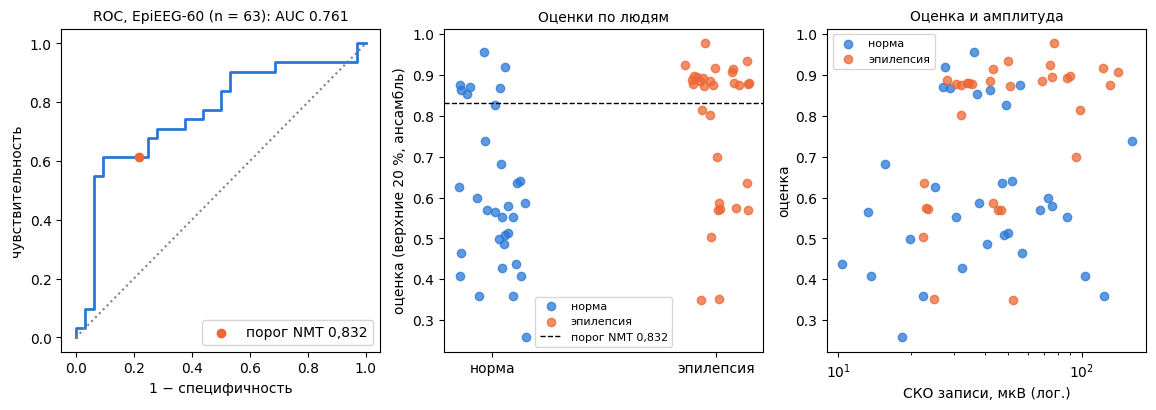

In [ ]:
d = view(); y, s = d.y.to_numpy(), d.reve4_ens_prob.to_numpy()
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
fpr, tpr, _ = roc_curve(y, s); ax[0].plot(fpr, tpr, color="#2a78d6", lw=2); ax[0].plot([0, 1], [0, 1], ":", color="gray")
pr_ = s >= 0.832; ax[0].scatter([(pr_ & (y == 0)).sum() / (y == 0).sum()], [(pr_ & (y == 1)).sum() / (y == 1).sum()], color="#eb6834", zorder=3, label="порог NMT 0,832")
ax[0].set(xlabel="1 − специфичность", ylabel="чувствительность", title=f"ROC, EpiEEG-60 (n = {len(y)}): AUC {roc_auc_score(y, s):.3f}"); ax[0].legend(loc="lower right")
for c, col, nm in [(0, "#2a78d6", "норма"), (1, "#eb6834", "эпилепсия")]:
    ax[1].scatter(np.full((y == c).sum(), c) + np.random.default_rng(c).uniform(-.15, .15, (y == c).sum()), s[y == c], color=col, alpha=.75, label=nm)
ax[1].axhline(0.832, color="k", ls="--", lw=1, label="порог NMT 0,832"); ax[1].set_xticks([0, 1], ["норма", "эпилепсия"])
ax[1].set(ylabel="оценка (верхние 20 %, ансамбль)", title="Оценки по людям"); ax[1].legend(fontsize=8)
for c, col, nm in [(0, "#2a78d6", "норма"), (1, "#eb6834", "эпилепсия")]:
    ax[2].scatter(d.std_uv[y == c], s[y == c], color=col, alpha=.75, label=nm)
ax[2].set_xscale("log"); ax[2].set(xlabel="СКО записи, мкВ (лог.)", ylabel="оценка", title="Оценка и амплитуда"); ax[2].legend(fontsize=8)
save_png(fig, "epieeg60_reve_v4.png")
print("файлы:", sorted(os.listdir(OUT)), sorted(os.listdir(FIG)))
print(f"всё время: {(time.time()-T_NB)/60:.1f} мин")


# EpiEEG-60: даты в служебных файлах по группам (CPU)
Строки вида «EEG-1100C ГГММДД» в `.CMT` и год в `.LOG`. Цель — проверить, не записаны ли группы в разное время.


In [ ]:
import os, re, glob, zipfile, requests, hashlib, collections
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu
API = "https://data.mendeley.com/public-api/datasets/gg88rc79vv"
f = [x for x in requests.get(f"{API}/files?folder_id=root&version=4", timeout=60).json() if x["filename"] == "BUBT_EEG.zip"][0]
p = "/tmp/BUBT_EEG.zip"; h = hashlib.sha256()
with requests.get(f["content_details"]["download_url"], stream=True, timeout=120) as r, open(p, "wb") as fo:
    for c in r.iter_content(1 << 22): fo.write(c); h.update(c)
assert h.hexdigest() == f["content_details"]["sha256_hash"]
zf = zipfile.ZipFile(p)
ASCII = re.compile(rb"[\x20-\x7e]{4,}")
rows = []
for n in zf.namelist():
    e = os.path.splitext(n)[1].upper()
    if e not in {".CMT", ".LOG", ".EEG"} or "/TRD" in n.upper(): continue
    grp = "Abnormal" if "/Abnormal/" in n else "Normal"; pat = os.path.splitext(os.path.basename(n))[0]
    b = zf.read(n) if e != ".EEG" else zf.open(n).read(4096)
    for s in ASCII.findall(b):
        s = s.decode()
        for m in re.finditer(r"EEG-1100C\s+(\d{6})", s, re.I):
            rows.append(dict(group=grp, patient=pat, file=e, date=m.group(1)))
        if e == ".EEG":
            for m in re.finditer(r"(?<!\d)(\d{12,14})(?!\d)", s):
                rows.append(dict(group=grp, patient=pat, file=e + " число", date=m.group(1)))
D = pd.DataFrame(rows)
print(D.groupby("file").size())
print("строк ГГММДД на запись (CMT):", D[D.file == ".CMT"].groupby("patient").size().describe().round(1).to_dict())
c = D[D.file == ".CMT"].groupby(["group", "patient"]).date.agg(["min", "max", "nunique"]).reset_index()
c["d"] = pd.to_datetime(c["min"], format="%y%m%d", errors="coerce")
print(c.groupby("group").d.describe())
print("по месяцам (первая дата в .CMT):\n", pd.crosstab(c.d.dt.to_period("M"), c.group))
a, b = c[c.group == "Normal"].d.dropna().astype("int64"), c[c.group == "Abnormal"].d.dropna().astype("int64")
print("Манн–Уитни по дате, p =", mannwhitneyu(a, b).pvalue)
e = D[D.file == ".EEG число"]; print("числа в заголовке .EEG (первые):", e.groupby("group").date.apply(lambda v: sorted(v.unique())[:5]).to_dict())
c.drop(columns="d").to_csv("/kaggle/working/epieeg60_dates.csv", index=False)


file
.CMT     63
.EEG    138
.LOG    126
dtype: int64
строк ГГММДД на запись (CMT): {'count': 63.0, 'mean': 1.0, 'std': 0.0, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 1.0}
         count                           mean                  min  \
group                                                                
Abnormal    31  2025-12-18 21:40:38.709677312  2025-11-29 00:00:00   
Normal      32            2025-12-05 03:00:00  2025-10-20 00:00:00   

                          25%                  50%                  75%  \
group                                                                     
Abnormal  2025-12-10 12:00:00  2025-12-20 00:00:00  2025-12-28 00:00:00   
Normal    2025-10-27 12:00:00  2025-12-14 12:00:00  2025-12-28 06:00:00   

                          max  
group                          
Abnormal  2026-01-10 00:00:00  
Normal    2026-01-08 00:00:00  
по месяцам (первая дата в .CMT):
 group    Abnormal  Normal
d                        
2025-10         0  

## Локальный пересчёт: порог в таблице калибровки
В выводе ядра (ячейка 3 части 2) столбец «значение_порога» усреднён, и при k = 10 среднее получилось `inf`. В 2–3 повторах из 499 Юден на 10 людях выбрал порог выше всех оценок, и тогда все остальные люди попадают в «норму». На метрики это не влияет. Ниже тот же расчёт по `epieeg60_per_person.csv` (63 строки, локально): вместо среднего порога — медиана и число таких повторов. Метрики совпали с выводом ядра (проверка `assert`), csv перезаписан.

In [ ]:
# локально, из h1_eeg/results: тот же расчёт, что в ячейке 3 части 2, плюс медиана порога и число повторов с порогом выше всех оценок
import numpy as np, pandas as pd
from sklearn.metrics import roc_curve
PP = pd.read_csv("epieeg60_per_person.csv")
def metr(y, pr):
    tp, tn = ((pr == 1) & (y == 1)).sum(), ((pr == 0) & (y == 0)).sum(); fp, fn = ((pr == 1) & (y == 0)).sum(), ((pr == 0) & (y == 1)).sum()
    rec = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1)
    return dict(acc=(tp + tn) / len(y), bacc=(rec + spec) / 2, prec=tp / (tp + fp) if tp + fp else np.nan, rec=rec, spec=spec)
def thr_youden(y, s):
    f, t, th = roc_curve(y, s); return th[np.argmax(t - f)]
def thr_sens(y, s, target=0.8):
    f, t, th = roc_curve(y, s); return th[np.where(t >= target)[0][0]]
res = []
for (v, a) in [("60 окон", "верхние 20 %"), ("все окна", "верхние 20 %"), ("60 окон", "медиана")]:
    d = PP[(PP["окна"] == v) & (PP["сборка"] == a)].reset_index(drop=True); y, s = d.y.to_numpy(), d.reve4_ens_prob.to_numpy()
    for k in [10, 20]:
        rng = np.random.default_rng(0)
        for rep in range(500):
            idx = rng.permutation(len(d)); cal, test = idx[:k], idx[k:]
            if len(set(y[cal])) < 2: continue
            for rule, f in [("Юден", thr_youden), ("recall 80 %", thr_sens)]:
                th = f(y[cal], s[cal])
                res.append(dict(калибровка=f"{k} чел.", окна=v, сборка=a, порог=rule, th=th, **metr(y[test], (s[test] >= th).astype(int))))
CR = pd.DataFrame(res); key = ["калибровка", "окна", "сборка", "порог"]
g = CR.drop(columns="th").groupby(key, sort=False)
CAL = (g.mean().round(2).astype(str) + " (" + g.quantile(.025).round(2).astype(str) + "–" + g.quantile(.975).round(2).astype(str) + ")")
CAL = CAL.rename(columns={"acc": "accuracy", "bacc": "сбаланс. accuracy", "prec": "precision", "rec": "recall", "spec": "специфичность"}).reset_index()
gt = CR.groupby(key, sort=False).th
CAL.insert(4, "повторов", gt.size().values)
CAL.insert(5, "порог: медиана (2,5–97,5 %)", (gt.median().round(3).astype(str) + " (" + gt.quantile(.025).round(2).astype(str) + "–" + gt.quantile(.975).round(2).astype(str) + ")").values)
CAL.insert(6, "повторов с порогом выше всех оценок", CR.assign(i=np.isinf(CR.th)).groupby(key, sort=False).i.sum().values)
old = pd.read_csv("epieeg60_local_threshold_calibration.csv")
for c in ["accuracy", "сбаланс. accuracy", "precision", "recall", "специфичность"]:
    assert (old[c].values == CAL[c].values).all(), c
CAL.to_csv("epieeg60_local_threshold_calibration.csv", index=False)
pd.set_option("display.width", 250)
print(CAL.to_string(index=False))


калибровка     окна       сборка       порог  повторов порог: медиана (2,5–97,5 %)  повторов с порогом выше всех оценок         accuracy сбаланс. accuracy        precision           recall    специфичность
   10 чел.  60 окон верхние 20 %        Юден       499           0.872 (0.57–0.91)                                    2 0.68 (0.54–0.75)  0.68 (0.54–0.76) 0.75 (0.55–0.93) 0.57 (0.15–0.92) 0.78 (0.38–0.96)
   10 чел.  60 окон верхние 20 % recall 80 %       499           0.574 (0.35–0.88)                                    0  0.65 (0.5–0.74)   0.65 (0.5–0.73) 0.66 (0.49–0.91)  0.74 (0.32–1.0) 0.56 (0.03–0.96)
   20 чел.  60 окон верхние 20 %        Юден       500           0.872 (0.57–0.88)                                    0 0.69 (0.56–0.79)  0.69 (0.57–0.78) 0.77 (0.53–0.93) 0.59 (0.27–0.91) 0.78 (0.33–0.96)
   20 чел.  60 окон верхние 20 % recall 80 %       500           0.571 (0.35–0.88)                                    0 0.65 (0.53–0.74)  0.66 (0.53–0.74)  0.64 (0.5–0.86)   0.

## Локально: оценки по месяцу записи
Дата — из строки «EEG-1100C ГГММДД» в `.CMT` (часть 3). Октябрь 2025 — только здоровые.

In [ ]:
# локально, из h1_eeg/results: оценка REVE v4 по месяцу записи (дата из .CMT, часть 3)
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
d = pd.read_csv("epieeg60_dates.csv", dtype={"min": str}); d["person"] = d.group + "_" + d.patient + ".EEG"
p = pd.read_csv("epieeg60_per_person.csv")
p = p[(p["окна"] == "60 окон") & (p["сборка"] == "верхние 20 %")].merge(d[["person", "min"]], on="person")
p["октябрь_2025"] = p["min"].str[:4] == "2510"
print(p.groupby(["y", "октябрь_2025"]).reve4_ens_prob.agg(["size", "median"]).round(3))
q = p[~p["октябрь_2025"]]; y, s = q.y.values, q.reve4_ens_prob.values
r = np.random.default_rng(0); b = [roc_auc_score(y[i], s[i]) for i in (r.integers(0, len(y), len(y)) for _ in range(2000)) if len(set(y[i])) == 2]
print(f"ROC AUC без записей октября 2025: {roc_auc_score(y, s):.3f} ({np.percentile(b, 2.5):.2f}–{np.percentile(b, 97.5):.2f}), n = {len(q)}")


                size  median
y октябрь_2025              
0 False           23   0.579
  True             9   0.513
1 False           31   0.878
ROC AUC без записей октября 2025: 0.736 (0.59–0.88), n = 54
